# The smooth standard incomplete markets (SIM) model

Higher-order approximations require reliable higher-order derivatives. This notebook introduces the smooth standard incomplete markets (SIM) model and compares it with a more conventional discrete implementation of the same calibration. We show that their steady states and first-order impulse responses are very close, but higher-order numerical derivatives behave very differently, with the smooth model being far more robust.

Households face the budget constraint
$$c_t+a_t=(1+r_t)a_{t-1}+Z_t e_t\xi_t+\mathrm{Tr}_t,\qquad a_t\geq0.$$
Persistent income $e_t$ and the discount factor follow finite-state Markov chains. The smooth model has a continuous iid income component, $\log\xi_t\sim N(-\sigma_\xi^2/2,\sigma_\xi^2)$, where $E[\xi_t]=1$, and we carefully integrate this component using quadrature applied separately on both sides of the kink. As the paper explains in appendix C, this approach is necessary for the computation to preserve the smoothness of the underlying model, and not to propagate "secondary kinks" and other pathologies that often emerge as artifacts of discretization. See `smooth_sim/` for the underlying code.

The "discrete" comparison model, by contrast, uses a standard Rouwenhorst discretization into 5 states—the same kind that we use for the persistent component—for the iid component, and then uses our standard SIM solution code (with linear interpolation for the policy function and lotteries to propagate the distribution), leaving every other aspect of the calibration unchanged. See `discrete_sim/` for the underlying code.

For some additional background on the discrete model's standard solution techniques, see the [2026 Goethe workshop](https://github.com/shade-econ/goethe-workshop-2026) materials for it ([slides](https://shade-econ.github.io/goethe-workshop-2026/lecture1_sim.pdf) and [notebook](https://github.com/shade-econ/goethe-workshop-2026/blob/main/supplements/sim_steady_state_computation.ipynb)). The workshop also has slides on the smooth SIM model ([slides](https://shade-econ.github.io/goethe-workshop-2026/lecture13_smooth.pdf)).

We calibrate the model's income process to hit facts about US income risk at both high and low frequency. We also calibrate the steady-state lump-sum transfer $Tr$ and level of after-tax aggregate income $Z$ to be consistent with the progressivity of the US tax system. The model also features heterogeneity in discount factors, calibrated to hit simultaneously an average MPC of 0.2 and an asset level of one year of GDP. See the paper's section 2.2 and appendix A.5 for details of this calibration.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from smooth_sim.model import paper_household as smooth_household
from discrete_sim.calibration import paper_steady_state as discrete_household
from discrete_sim.sim_transition import transition

plt.rcParams["figure.figsize"] = (7, 3.5)
hh, ss = smooth_household() # steady state for smooth model

## 1. Steady states under the same calibration

We first solve the discrete model using the same parameters as the smooth model: the same persistent income and discount-factor processes, interest rate, transfers, and 200-point asset grid on $[0,1000]$. The five-state approximation to iid income has the same mean, $E[\xi]=1$, and the same log variance, $\operatorname{Var}(\log\xi)=\sigma_\xi^2$, as the smooth model.

As described above, the discount factors are calibrated in the smooth model to target assets of one year's GDP and an impact income MPC of 0.2. We leave them unchanged in the discrete model. Steady-state quarterly GDP is normalized to one.

In [2]:
ss_discrete = discrete_household()

print(f"{'Steady state':<18} {'Smooth':>10} {'Discrete':>10}")
for name, key in [("Assets", "A"), ("Consumption", "C")]:
    print(f"{name:<18} {ss[key]:10.5f} {ss_discrete[key]:10.5f}")

Steady state           Smooth   Discrete
Assets                4.00000    4.01305
Consumption           0.83000    0.83006


We see that the steady-state aggregates are almost unchanged: assets are 4.000 in the smooth model and 4.013 in the discrete model, while consumption is 0.830 in both to three decimal places.

## 2. Asset distributions near the borrowing constraint

Similar aggregates need not imply similar distributions, particularly near the borrowing constraint. Below we compare the asset CDFs for households with the low discount factor and the middle persistent-income state, integrating out iid income in the discrete model.

We zoom in near zero, where the borrowing constraint matters most. This adds a discrete comparison to the conditional asset CDFs in paper **Figure C.6(b)**.

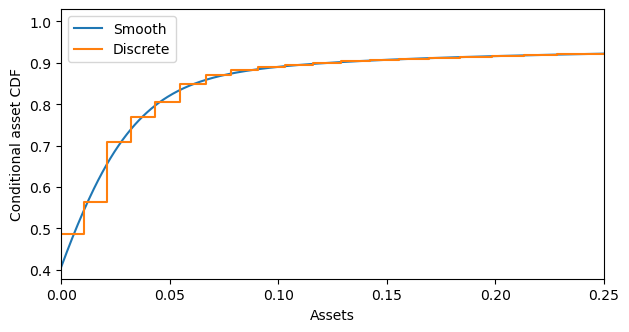

In [3]:
# Paper Figure C.6(b), with an added discrete-model comparison.
D = ss_discrete["D"].reshape(len(hh.e), len(ss_discrete["xi"]), len(hh.a_grid)).sum(axis=1)
state = 3  # Low discount factor, middle persistent-income state.
F_discrete = D[state].cumsum() / hh.pi[state]
assets = np.linspace(0., 0.25, 400)
plt.plot(assets, CubicSpline(hh.a_grid, ss["F"][state])(assets), label="Smooth")
plt.step(hh.a_grid, F_discrete, where="post", label="Discrete")
plt.xlim(0, 0.25)
plt.xlabel("Assets"); plt.ylabel("Conditional asset CDF")
plt.legend();

Both models have a mass point at zero assets. Above zero, the discrete implementation also places mass at individual asset-grid points, which show up as steps in the CDF. More revealing is how uneven these mass points are: the second and fifth positive grid points have noticeably more mass than their neighbors, with no comparable feature in the smooth CDF. These concentrations largely reflect households leaving the borrowing constraint, whose discrete income realizations send them to a few particular saving levels. Continuous iid income spreads these households across a range of assets.

These mass points matter for more than the shape of the distribution. As an aggregate shock moves a mass point across a kink in the individual consumption policy, the aggregate consumption response can itself have a kink: its first derivative jumps, and its second derivative is undefined there. The smooth model retains the individual policy kink at the borrowing constraint, but continuous iid income smooths the aggregate response by averaging over it. Importantly, splitting the integrals at the constraint preserves this property in the computation.

## 3. Consumption responses to an income shock

We next compare consumption after a one-time proportional income shock, $\Delta Z_0=z$. Each household receives additional income $ze_0\xi_0$ on impact, with interest rates, transfers, and future aggregate income held fixed. Since $e\xi$ has mean one, the aggregate income injection is $z$.

Let $C_t(z)$ denote aggregate consumption at date $t$ following this shock. The left panel estimates the first-order MPC $C_t'(0)$ using a small centered difference. The right panel shows a nonlinear MPC for a shock of 10% of quarterly GDP: $[C_t(0.10)-C_t(0)]/0.10$. Both measure consumption per unit of the initial income shock and use the same vertical scale.

Smooth impact income MPC: 0.20000


Discrete impact income MPC: 0.19863


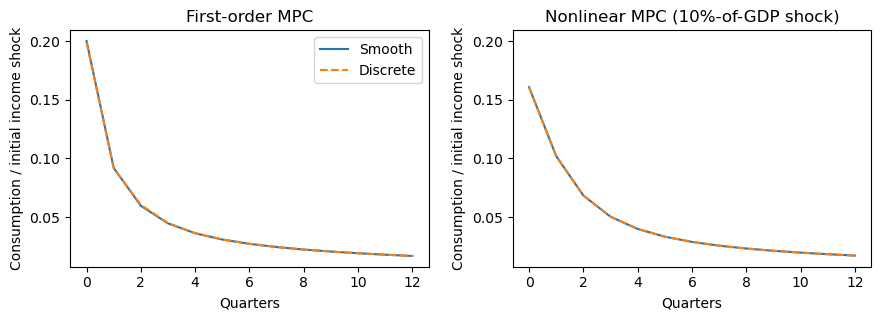

In [4]:
def smooth_consumption(z, T=1):
    return hh.transition(ss, dZ=np.concatenate(([z], np.zeros(T-1))))["C"]

def discrete_consumption(z, T=1):
    dy = np.concatenate(([z], np.zeros(T-1)))[:, None]*ss_discrete["e"]
    return transition(ss_discrete, T, dy=dy)[1]

T, h, shock = 300, 1e-4, 0.10
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for consumption, label, style in [(smooth_consumption, "Smooth", "-"),
                                  (discrete_consumption, "Discrete", "--")]:
    C1 = (consumption(h, T)-consumption(-h, T))/(2*h)
    response = (consumption(shock, T)-consumption(0., T))/shock
    axes[0].plot(np.arange(13), C1[:13], style, label=label)
    axes[1].plot(np.arange(13), response[:13], style, label=label)
    print(f"{label} impact income MPC: {C1[0]:.5f}")
axes[0].set_title("First-order MPC")
axes[1].set_title("Nonlinear MPC (10%-of-GDP shock)")
axes[1].set_ylim(axes[0].get_ylim())
for ax in axes:
    ax.set(xlabel="Quarters", ylabel="Consumption / initial income shock")
axes[0].legend()
fig.tight_layout();

We see that the two implementations give almost identical consumption responses in both panels. The impact income MPC is 0.200 in the smooth model and about 0.199 in the discrete model. (Note that the "smooth" lines in these plots are the first-order and nonlinear lines in the paper's **Figure 1(a)**.)

For a shock of 10% of quarterly GDP, the impact MPC falls from about 0.20 to 0.16, a decline of roughly 20%. The agreement between the two implementations therefore extends beyond their first-order responses: both capture this nonlinear effect closely. As we will see next, this agreement for a sizable shock contrasts with very different behavior for higher-order numerical derivatives under the two methods.

## 4. Higher derivatives: reliable for smooth, unreliable for discrete

We now estimate the first three derivatives of impact consumption $C_0(z)$, applying the same centered differences to both models:
$$
D_1(h)=\frac{C_0(h)-C_0(-h)}{2h},\qquad
D_2(h)=\frac{C_0(h)-2C_0(0)+C_0(-h)}{h^2},
$$
$$
D_3(h)=\frac{C_0(-3h)-8C_0(-2h)+13C_0(-h)-13C_0(h)+8C_0(2h)-C_0(3h)}{8h^3}.
$$
For the third derivative, we use the same "seven-point" stencil as in the paper. We vary $h$ from $10^{-4}$ to $10^{-2}$, or step sizes of 0.01% to 1% of quarterly GDP, and look for a range over which the derivative estimates are stable.

Because the shock lasts only one period and we only need impact consumption, we can hold continuation values at steady state and solve just the impact period. The figure below corresponds to the step-size experiment in paper **Figure C.7**.

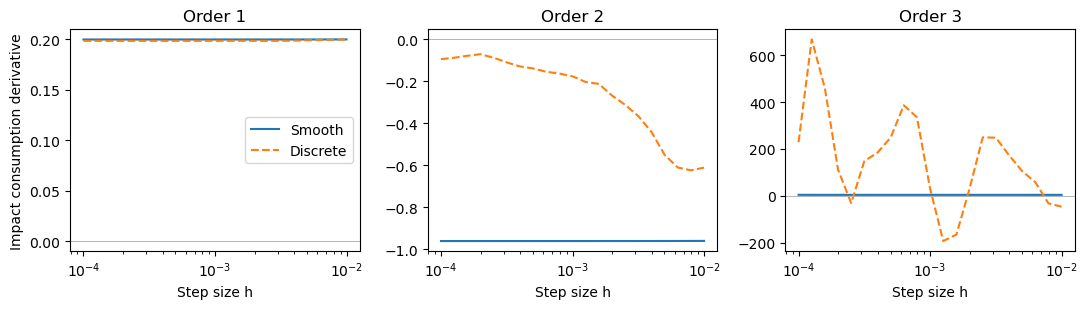

In [5]:
# Paper Figure C.7.
steps = np.geomspace(1e-4, 1e-2, 21)

def impact_derivatives(consumption):
    C0 = consumption(0.)[0]
    derivatives = []
    for h in steps:
        Cm3, Cm2, Cm, Cp, Cp2, Cp3 = [consumption(z)[0] for z in (-3*h, -2*h, -h, h, 2*h, 3*h)]
        derivatives.append([(Cp-Cm)/(2*h), (Cp-2*C0+Cm)/h**2,
                            (Cm3-8*Cm2+13*Cm-13*Cp+8*Cp2-Cp3)/(8*h**3)])
    return np.array(derivatives)

smooth_derivatives = impact_derivatives(smooth_consumption)
discrete_derivatives = impact_derivatives(discrete_consumption)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for order, ax in enumerate(axes):
    ax.semilogx(steps, smooth_derivatives[:, order], label="Smooth")
    ax.semilogx(steps, discrete_derivatives[:, order], "--", label="Discrete")
    ax.axhline(0., color="0.7", linewidth=0.7)
    ax.set(title=f"Order {order+1}", xlabel="Step size h")
axes[0].set_ylabel("Impact consumption derivative")
axes[0].legend()
fig.tight_layout();

We see that the first derivative is stable and close in the two models. At higher orders, however, the comparison changes sharply. The smooth model gives nearly constant estimates over this range of step sizes. But the discrete model's second derivative varies substantially, and its third derivative even changes sign, with wildly varying magnitudes.

The discrete calculation combines piecewise-linear policy functions with a distribution concentrated at asset-grid points. As the aggregate shock varies, a mass of households can cross a policy kink together, creating an abrupt change in the slope of aggregate consumption. Changing $h$ changes which kinks are spanned by the finite-difference calculation, and division by $h^2$ or $h^3$ makes the higher-order estimates sensitive even to small changes in slope.

These kinks and mass points are not solely consequences of the discrete model's solution techniques (linear interpolation and asset-grid lotteries). As we noted earlier, discrete income shocks themselves propagate the borrowing-constraint kink to secondary kinks in the policy function, and send households leaving the constraint to particular asset levels. These kinks and mass points make it difficult to approximate the policies and distributions accurately with smooth representations; changing the representation alone does not remove the underlying nonsmoothness.

Summing up: despite the two implementations agreeing closely on steady-state aggregates, first-order responses, and even the nonlinear response to a sizable income shock, they differ substantially on higher-order derivatives, where the discrete implementation is highly sensitive to the differentiation step. The smooth model preserves the borrowing constraint and its economic effects while delivering stable higher-order derivatives, making it our starting point for the higher-order calculations in notebook 1.